# 10 · Mass action and experimental electrolyte models

**Requirements:** core package and tutorial plotting dependencies.

Run this notebook from top to bottom in the environment where ThermoWeave is installed. All examples are self-contained unless explicitly marked optional. See the [course index](../../tutorials.md) and [theory guide](../../theory.md).

<a class="md-button" href="synthetic_reactive_electrolytes.ipynb" download>Download notebook</a>


## Reaction equilibrium at fixed T
 For a stoichiometric matrix ν, equilibrium satisfies $\nu^T\ln a=\ln K$.
 We use synthetic isomers A ⇌ B with K=4, equal molecular mass and ideal liquid
 activities. This example is a homogeneous mass-action solve, not a reactive
 multi-phase stability certificate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import ThermodynamicModel
from thermoweave.model import mole_fractions

class RegularSolution(ThermodynamicModel):
    """Synthetic binary two-suffix Margules model; A is dimensionless."""
    def __init__(self, A=0.0):
        self.A = float(A)
    @property
    def n_components(self):
        return 2
    def ln_activity_coefficients(self, temperature_K, x, pressure_Pa=None):
        x = mole_fractions(x, 2)
        return self.A * np.array([x[1]**2, x[0]**2])

In [2]:
from thermoweave.equilibrium.reactive import solve_reaction_extents
model = RegularSolution(A=0.)
n_eq, extent, converged = solve_reaction_extents(model, 298.15, [0.8, 0.2],
                                               [-1., 1.], [np.log(4.)])
print('Equilibrium mole numbers:', n_eq, '; extent:', extent, '; converged:', converged)
assert converged
np.testing.assert_allclose(n_eq/n_eq.sum(), [0.2, 0.8], atol=1e-8)
np.testing.assert_allclose(n_eq.sum(), 1., atol=1e-12)

Equilibrium mole numbers: [0.2 0.8] ; extent: [0.6] ; converged: True


## Synthetic electrolyte free energy
 `ToyElectrolyteModel` combines a Margules short-range contribution with a
 mole-fraction-based Pitzer–Debye–Hückel-like long-range term. The parameters
 below are **synthetic**, not fitted salt data. We follow neutral water/salt
 compositions so $\sum_i x_i z_i=0$.

 The production-facing `ElectrolyteModel` and ME-PDH data structures are separate
 experimental tools; ionic standard states, parameter provenance and charge
 conservation require care. The SAFT EOS does not acquire ionic/Born terms
 merely by accepting a charged group table.

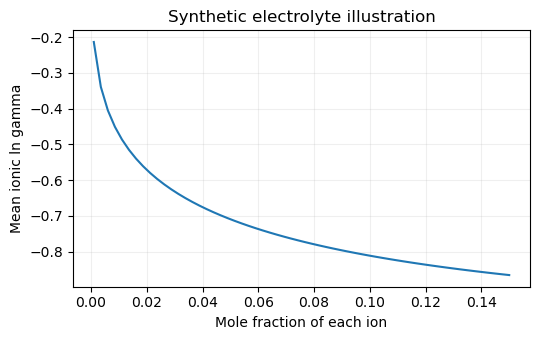

In [3]:
from thermoweave.electrolyte.toy import ToyElectrolyteModel
charges = np.array([0., 1., -1.])  # water, cation, anion
toy = ToyElectrolyteModel(np.zeros((3, 3)), charges)
salt_fractions = np.linspace(0.001, 0.15, 60)
values = []
for s in salt_fractions:
    composition = np.array([1-2*s, s, s])
    assert abs(charges @ composition) < 1e-15
    lng = toy.ln_activity_coefficients(298.15, composition)
    values.append(0.5*(lng[1]+lng[2]))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(salt_fractions, values)
ax.set(xlabel='Mole fraction of each ion', ylabel='Mean ionic ln gamma',
       title='Synthetic electrolyte illustration')
ax.grid(alpha=0.2); fig.tight_layout(); plt.show()

**Try:** change K in the ideal reaction example and verify the analytic
 composition K/(1+K). For real electrolytes, use consistent standard potentials
 and electroneutral component definitions; do not interpret this synthetic
 curve as a salt-solubility or electrolyte-EOS prediction.

 See [capabilities](../../capabilities.md) before extending this example to
 reactive/electrolyte phase equilibrium.